<a href="https://colab.research.google.com/github/luthfiahrahmawati982-boop/praktikum-machine-learning/blob/main/Pratikum_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Praktikum Machine Learning_8


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report,accuracy_score

In [3]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train,X_test,y_train,y_test = train_test_split(X,y,
test_size=0.2,random_state=42,stratify=y)

In [9]:
# SVM sangat sensitif terhadap skala fitur,scaling WAJIB dilakukan
pipeline = Pipeline([ ("scaler",StandardScaler()),("svm",SVC()) ])

In [10]:
param_grid = { "svm__C": [0.1,1,10,100],
"svm__gamma": [0.001,0.01,0.1,1],"svm__kernel": ["rbf",
"linear"] }
grid_search = GridSearchCV(pipeline,param_grid,cv=5,
scoring="f1",n_jobs=-1)
grid_search.fit(X_train, y_train)
print("Parameter terbaik:", grid_search.best_params_)
print("F1-Score terbaik (CV):",
round(grid_search.best_score_,3))

Parameter terbaik: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
F1-Score terbaik (CV): 0.984


In [11]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print("Akurasi Test:",round(accuracy_score(y_test,y_pred),
3))
print(classification_report(y_test, y_pred))

Akurasi Test: 0.982
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



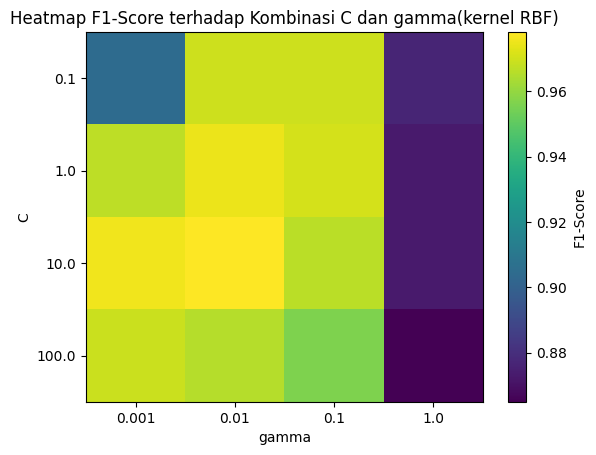

In [13]:
import pandas as pd
hasil = pd.DataFrame(grid_search.cv_results_)
pivot = hasil.pivot_table(values="mean_test_score",
index="param_svm__C",columns="param_svm__gamma")
plt.imshow(pivot, cmap="viridis", aspect="auto")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("gamma"); plt.ylabel("C")
plt.title("Heatmap F1-Score terhadap Kombinasi C dan gamma(kernel RBF)")
plt.colorbar(label="F1-Score")
plt.show()